# Train YOLOv8 nano model on local laptop

In [3]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(data = "data.yaml", imgsz=640, batch=8, epochs=150, workers=4, device=0)

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.117  Python-3.14.2 torch-2.12.0.dev20260408+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 12, 13, 14, 15, 16])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000248F0221D30>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.04

# Test YOLOv8n_custom model via webcam for real-time hand-gesture detection

In [7]:
from pathlib import Path
from ultralytics import YOLO
import cv2
import threading
from queue import Queue

model = YOLO("yolov8n_custom.pt")

# Video capture with threading for non-blocking reading
class FrameCapture:
    def __init__(self, source=0, fps_limit=30):
        self.cap = cv2.VideoCapture(source)
        self.cap.set(cv2.CAP_PROP_FPS, fps_limit)
        self.frame = None
        self.running = True
        self.thread = threading.Thread(target=self.read_frames, daemon=True)
        self.thread.start()
    
    def read_frames(self):
        while self.running:
            ret, frame = self.cap.read()
            if ret:
                self.frame = frame
    
    def get_frame(self):
        return self.frame
    
    def release(self):
        self.running = False
        self.cap.release()

# Start capture with FPS limit
frame_reader = FrameCapture(source=0, fps_limit=30)

print("Starting webcam detection...")
print("Press 'q' to quit")

frame_count = 0
skip_frames = 2  # Process every 3rd frame for speed

try:
    while True:
        frame = frame_reader.get_frame()
        if frame is None:
            continue
        
        frame_count += 1
        
        # Skip frames for real-time performance
        if frame_count % (skip_frames + 1) != 0:
            continue
        
        # Resize for faster inference (optional)
        resized = cv2.resize(frame, (640, 480))
        
        # Predict with confidence threshold
        results = model.predict(
            source=resized,
            device=0,
            conf=0.5,  # Only detections > 50% confidence
            imgsz=640,
            verbose=False
        )
        
        # Draw results
        for r in results:
            frame = r.plot()
        
        cv2.imshow("YOLO Detection", frame)
        
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

finally:
    frame_reader.release()
    cv2.destroyAllWindows()
    print("Webcam detection stopped")

Starting webcam detection...
Press 'q' to quit
Webcam detection stopped


# Confusion Matrix for YOLOv8n_custom model (using image and label in test folder)

In [3]:
from pathlib import Path
from ultralytics import YOLO

model = YOLO("yolov8n_custom.pt")
test_images = Path("test/images")
test_labels = Path("test/labels")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not test_images.is_dir():
    raise FileNotFoundError(f"Test image directory not found: {test_images.resolve()}")
if not test_labels.is_dir():
    raise FileNotFoundError(f"Test label directory not found: {test_labels.resolve()}")

image_paths = sorted(
    path for path in test_images.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)
if not image_paths:
    raise FileNotFoundError(f"No test images found in {test_images.resolve()}")

true_ids = []
predicted_ids = []
for image_path in image_paths:
    label_path = test_labels / f"{image_path.stem}.txt"
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing label for {image_path.name}: {label_path}")

    label_lines = [
        line.split()
        for line in label_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    if len(label_lines) != 1 or len(label_lines[0]) < 5:
        raise ValueError(f"Expected one YOLO object label in {label_path}")

    true_id = int(label_lines[0][0])
    if true_id not in model.names:
        raise ValueError(f"Unknown class id {true_id} in {label_path}")

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False,
    )[0]
    predicted_id = None
    if result.boxes is not None and len(result.boxes):
        best_index = int(result.boxes.conf.argmax().item())
        predicted_id = int(result.boxes.cls[best_index].item())

    true_ids.append(true_id)
    predicted_ids.append(predicted_id)

# Evaluate one-vs-rest metrics for classes present in labels or predictions.
class_ids = sorted(set(true_ids) | {value for value in predicted_ids if value is not None})
class_metrics = {}
for class_id in class_ids:
    true_positive = sum(
        actual == class_id and predicted == class_id
        for actual, predicted in zip(true_ids, predicted_ids)
    )
    false_negative = sum(
        actual == class_id and predicted != class_id
        for actual, predicted in zip(true_ids, predicted_ids)
    )
    false_positive = sum(
        actual != class_id and predicted == class_id
        for actual, predicted in zip(true_ids, predicted_ids)
    )
    true_negative = len(true_ids) - true_positive - false_negative - false_positive

    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
    specificity = true_negative / (true_negative + false_positive) if true_negative + false_positive else 0.0
    f1_score = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    class_metrics[class_id] = {
        "support": sum(actual == class_id for actual in true_ids),
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1_score,
    }

accuracy = sum(actual == predicted for actual, predicted in zip(true_ids, predicted_ids)) / len(true_ids)
print(f"Images evaluated: {len(image_paths)}")
print(f"Accuracy:         {accuracy:.2%}")
for metric_name in ("precision", "recall", "specificity", "f1"):
    macro_score = sum(metrics[metric_name] for metrics in class_metrics.values()) / len(class_metrics)
    print(f"Macro {metric_name.capitalize():<12} {macro_score:.2%}")

print("\nPer-class metrics (one-vs-rest):")
print(f"{'Class':<14} {'Support':>7} {'Precision':>11} {'Recall':>10} {'Specificity':>13} {'F1':>9}")
for class_id, metrics in class_metrics.items():
    class_name = model.names[class_id]
    print(
        f"{class_name:<14} {metrics['support']:>7} "
        f"{metrics['precision']:>10.2%} {metrics['recall']:>9.2%} "
        f"{metrics['specificity']:>12.2%} {metrics['f1']:>8.2%}"
    )
print(f"No detections: {sum(predicted is None for predicted in predicted_ids)}")


Images evaluated: 23
Accuracy:         82.61%
Macro Precision    71.88%
Macro Recall       72.92%
Macro Specificity  99.44%
Macro F1           71.67%

Per-class metrics (one-vs-rest):
Class          Support   Precision     Recall   Specificity        F1
I                    0      0.00%     0.00%       95.65%    0.00%
apple                1      0.00%     0.00%      100.00%    0.00%
can                  1    100.00%   100.00%      100.00%  100.00%
get                  2    100.00%   100.00%      100.00%  100.00%
good                 2    100.00%   100.00%      100.00%  100.00%
have                 1    100.00%   100.00%      100.00%  100.00%
help                 1    100.00%   100.00%      100.00%  100.00%
like                 3    100.00%    66.67%      100.00%   80.00%
love                 1    100.00%   100.00%      100.00%  100.00%
no                   1    100.00%   100.00%      100.00%  100.00%
sorry                1      0.00%     0.00%      100.00%    0.00%
thank-you           

# Confusion Matrix for YOLOv8n_custom model (using image and label in test_selfie folder)

In [9]:
from pathlib import Path
from ultralytics import YOLO

model = YOLO("yolov8n_custom.pt")
test_images = Path("test_selfie/images")
test_labels = Path("test_selfie/labels")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not test_images.is_dir():
    raise FileNotFoundError(f"Test image directory not found: {test_images.resolve()}")
if not test_labels.is_dir():
    raise FileNotFoundError(f"Test label directory not found: {test_labels.resolve()}")

image_paths = sorted(
    path for path in test_images.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)
if not image_paths:
    raise FileNotFoundError(f"No test images found in {test_images.resolve()}")

true_ids = []
predicted_ids = []
for image_path in image_paths:
    label_path = test_labels / f"{image_path.stem}.txt"
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing label for {image_path.name}: {label_path}")

    label_lines = [
        line.split()
        for line in label_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    if len(label_lines) != 1 or len(label_lines[0]) < 5:
        raise ValueError(f"Expected one YOLO object label in {label_path}")

    true_id = int(label_lines[0][0])
    if true_id not in model.names:
        raise ValueError(f"Unknown class id {true_id} in {label_path}")

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False,
    )[0]
    predicted_id = None
    if result.boxes is not None and len(result.boxes):
        best_index = int(result.boxes.conf.argmax().item())
        predicted_id = int(result.boxes.cls[best_index].item())

    true_ids.append(true_id)
    predicted_ids.append(predicted_id)

# Evaluate one-vs-rest metrics for classes present in the test labels.
class_ids = sorted(set(true_ids))
class_metrics = {}
for class_id in class_ids:
    true_positive = sum(
        actual == class_id and predicted == class_id
        for actual, predicted in zip(true_ids, predicted_ids)
    )
    false_negative = sum(
        actual == class_id and predicted != class_id
        for actual, predicted in zip(true_ids, predicted_ids)
    )
    false_positive = sum(
        actual != class_id and predicted == class_id
        for actual, predicted in zip(true_ids, predicted_ids)
    )
    true_negative = len(true_ids) - true_positive - false_negative - false_positive

    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
    specificity = true_negative / (true_negative + false_positive) if true_negative + false_positive else 0.0
    f1_score = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    class_metrics[class_id] = {
        "support": sum(actual == class_id for actual in true_ids),
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1_score,
    }

accuracy = sum(actual == predicted for actual, predicted in zip(true_ids, predicted_ids)) / len(true_ids)
print(f"Images evaluated: {len(image_paths)}")
print(f"Accuracy:         {accuracy:.2%}")
for metric_name in ("precision", "recall", "specificity", "f1"):
    macro_score = sum(metrics[metric_name] for metrics in class_metrics.values()) / len(class_metrics)
    print(f"Macro {metric_name.capitalize():<12} {macro_score:.2%}")

print("\nPer-class metrics (one-vs-rest):")
print(f"{'Class':<14} {'Support':>7} {'Precision':>11} {'Recall':>10} {'Specificity':>13} {'F1':>9}")
for class_id, metrics in class_metrics.items():
    class_name = model.names[class_id]
    print(
        f"{class_name:<14} {metrics['support']:>7} "
        f"{metrics['precision']:>10.2%} {metrics['recall']:>9.2%} "
        f"{metrics['specificity']:>12.2%} {metrics['f1']:>8.2%}"
    )
print(f"No detections: {sum(predicted is None for predicted in predicted_ids)}")


Images evaluated: 160
Accuracy:         95.62%
Macro Precision    98.37%
Macro Recall       95.62%
Macro Specificity  99.73%
Macro F1           96.73%

Per-class metrics (one-vs-rest):
Class          Support   Precision     Recall   Specificity        F1
I                   20    100.00%   100.00%      100.00%  100.00%
get                 20    100.00%   100.00%      100.00%  100.00%
good                20    100.00%   100.00%      100.00%  100.00%
help                20    100.00%   100.00%      100.00%  100.00%
love                20    100.00%    80.00%      100.00%   88.89%
sorry               20     86.96%   100.00%       97.86%   93.02%
want                20    100.00%   100.00%      100.00%  100.00%
you                 20    100.00%    85.00%      100.00%   91.89%
No detections: 4


# Interactive webcam detection for YOLOv8n_custom model:

In [1]:
import sys
from pathlib import Path

# Add the project root to PYTHONPATH using the Lawrence detector module.
# Resolve the project root robustly in a notebook context.
current = Path.cwd().resolve()
base = current

# Find the project root containing models/Lawrence/gesture_detector.py.
for candidate in [current, *current.parents]:
    if (candidate / "models" / "Lawrence" / "gesture_detector.py").is_file():
        base = candidate.resolve()
        break

# Ensure the project root is importable when the notebook is launched from elsewhere.
for candidate in [base, current, *current.parents]:
    if (candidate / "models" / "Lawrence" / "gesture_detector.py").is_file():
        sys.path.insert(0, str(candidate))
        break

from models.Lawrence.gesture_detector import GestureDetector

model_path = (base / "checkpoints" / "yolov8n_custom.pt").resolve()
if not model_path.exists():
    raise FileNotFoundError(f"Model file not found: {model_path}")

detector = GestureDetector(str(model_path), camera_index=0)
detector.run_interactive_loop()

Starting 5-second countdown. Show your hand gesture to the webcam.
Photo captured. Predicting gesture...
Prediction: No gesture detected
Press 'n' for next prediction or 'q' to quit
Starting 5-second countdown. Show your hand gesture to the webcam.
Photo captured. Predicting gesture...
Prediction: No gesture detected
Press 'n' for next prediction or 'q' to quit
Starting 5-second countdown. Show your hand gesture to the webcam.
Photo captured. Predicting gesture...
Prediction: get (43.1%)
Press 'n' for next prediction or 'q' to quit
Gesture detection finished.


# Single Webcam dectection:

In [4]:
detector = GestureDetector(str(model_path), camera_index=0)
if detector.open_camera():
    result = detector.run_with_countdown()
    print(f"Detected: {result['gesture']} ({result['confidence']:.1%})")
    detector.close_camera()

Starting 5-second countdown. Show your hand gesture to the webcam.
Photo captured. Predicting gesture...
Prediction: no (95.1%)
Detected: no (95.1%)


# Confusion Matrix Plots for YOLOv8n at 50, 100, 150 epochs (Prediction using image and label in test_selfie folder)

In [1]:
from pathlib import Path
from ultralytics import YOLO
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".tif"}

evaluation_images = Path("test_selfie/images")
evaluation_labels = Path("test_selfie/labels")
checkpoint_dir = next(
    parent / 'checkpoints' / 'retrain'
    for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (parent / 'models' / 'Lawrence' / 'gesture_detector.py').is_file()
)
model_paths = [str(checkpoint_dir / f'yolov8n{epoch}.pt') for epoch in (50, 100, 150)]

if not evaluation_images.is_dir():
    raise FileNotFoundError(f"Image directory not found: {evaluation_images.resolve()}")
if not evaluation_labels.is_dir():
    raise FileNotFoundError(f"Label directory not found: {evaluation_labels.resolve()}")

evaluation_image_paths = sorted(
    path for path in evaluation_images.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)
if not evaluation_image_paths:
    raise FileNotFoundError(f"No images found in {evaluation_images.resolve()}")

# Load and validate labels once; this evaluation expects one object per image.
evaluation_true_ids = []
for image_path in evaluation_image_paths:
    label_path = evaluation_labels / f"{image_path.stem}.txt"
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing label for {image_path.name}: {label_path}")

    lines = [
        line.split()
        for line in label_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    if len(lines) != 1 or len(lines[0]) < 5:
        raise ValueError(f"Expected one YOLO object label in {label_path}")
    evaluation_true_ids.append(int(lines[0][0]))

evaluation_reports = {}

for model_path in model_paths:
    if not Path(model_path).is_file():
        raise FileNotFoundError(f"Model file not found: {Path(model_path).resolve()}")

    evaluation_model = YOLO(model_path)
    evaluation_predicted_ids = []

    for image_path in evaluation_image_paths:
        result = evaluation_model.predict(
            source=str(image_path),
            imgsz=640,
            conf=0.25,
            device=0,
            verbose=False,
        )[0]

        predicted_id = None
        if result.boxes is not None and len(result.boxes):
            best_index = int(result.boxes.conf.argmax().item())
            predicted_id = int(result.boxes.cls[best_index].item())
        evaluation_predicted_ids.append(predicted_id)

    evaluation_class_ids = sorted(
        set(evaluation_true_ids)
        | {class_id for class_id in evaluation_predicted_ids if class_id is not None}
    )
    evaluation_class_metrics = {}

    for class_id in evaluation_class_ids:
        tp = sum(
            actual == class_id and predicted == class_id
            for actual, predicted in zip(evaluation_true_ids, evaluation_predicted_ids)
        )
        fn = sum(
            actual == class_id and predicted != class_id
            for actual, predicted in zip(evaluation_true_ids, evaluation_predicted_ids)
        )
        fp = sum(
            actual != class_id and predicted == class_id
            for actual, predicted in zip(evaluation_true_ids, evaluation_predicted_ids)
        )
        tn = len(evaluation_true_ids) - tp - fn - fp

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        specificity = tn / (tn + fp) if tn + fp else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

        evaluation_class_metrics[class_id] = {
            "support": sum(actual == class_id for actual in evaluation_true_ids),
            "precision": precision,
            "recall": recall,
            "specificity": specificity,
            "f1": f1,
        }

    evaluation_accuracy = sum(
        actual == predicted
        for actual, predicted in zip(evaluation_true_ids, evaluation_predicted_ids)
    ) / len(evaluation_true_ids)

    evaluation_macro = {
        metric: sum(values[metric] for values in evaluation_class_metrics.values())
        / len(evaluation_class_metrics)
        for metric in ("precision", "recall", "specificity", "f1")
    }

    evaluation_reports[model_path] = {
        "accuracy": evaluation_accuracy,
        "macro": evaluation_macro,
        "class_metrics": evaluation_class_metrics,
        "names": evaluation_model.names,
        "no_detections": sum(value is None for value in evaluation_predicted_ids),
        "true_ids": list(evaluation_true_ids),
        "predicted_ids": list(evaluation_predicted_ids),
    }

    print(f"\n=== {model_path} ===")
    print(f"Images evaluated: {len(evaluation_image_paths)}")
    print(f"Accuracy:         {evaluation_accuracy:.2%}")
    for metric_name, value in evaluation_macro.items():
        print(f"Macro {metric_name.capitalize():<12} {value:.2%}")

    print("\nPer-class metrics (one-vs-rest):")
    print(f"{'Class':<20} {'Support':>7} {'Precision':>11} {'Recall':>10} {'Specificity':>13} {'F1':>9}")
    for class_id, metrics in evaluation_class_metrics.items():
        names = evaluation_model.names
        class_name = names.get(class_id, str(class_id)) if isinstance(names, dict) else names[class_id]
        print(
            f"{class_name:<20} {metrics['support']:>7} "
            f"{metrics['precision']:>10.2%} {metrics['recall']:>9.2%} "
            f"{metrics['specificity']:>12.2%} {metrics['f1']:>8.2%}"
        )
    print(f"No detections: {evaluation_reports[model_path]['no_detections']}")

print("\n=== Model comparison ===")
print(f"{'Model':<20} {'Accuracy':>10} {'Macro Precision':>17} {'Macro Recall':>14} {'Macro F1':>10}")
for model_path, report in evaluation_reports.items():
    print(
        f"{model_path:<20} {report['accuracy']:>9.2%} "
        f"{report['macro']['precision']:>16.2%} "
        f"{report['macro']['recall']:>13.2%} "
        f"{report['macro']['f1']:>9.2%}"
    )


=== yolov8n50.pt ===
Images evaluated: 160
Accuracy:         96.88%
Macro Precision    87.44%
Macro Recall       86.11%
Macro Specificity  99.62%
Macro F1           86.66%

Per-class metrics (one-vs-rest):
Class                Support   Precision     Recall   Specificity        F1
I                         20     86.96%   100.00%       97.86%   93.02%
get                       20    100.00%   100.00%      100.00%  100.00%
good                      20    100.00%   100.00%      100.00%  100.00%
have                       0      0.00%     0.00%       98.75%    0.00%
help                      20    100.00%    95.00%      100.00%   97.44%
love                      20    100.00%   100.00%      100.00%  100.00%
sorry                     20    100.00%   100.00%      100.00%  100.00%
want                      20    100.00%    90.00%      100.00%   94.74%
you                       20    100.00%    90.00%      100.00%   94.74%
No detections: 0

=== yolov8n100.pt ===
Images evaluated: 160
Accurac

Written: reports\yolo_confusion.png


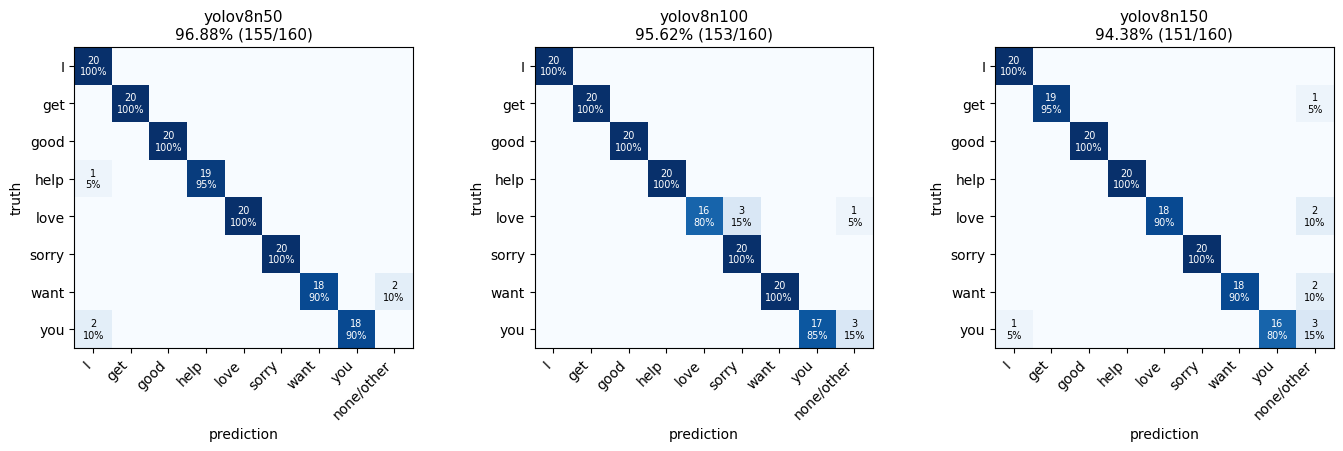

In [3]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

SAVE_ARTIFACTS = True
CONFUSION_PATH = Path("reports/yolo_confusion.png")
EVAL_WORDS = ["I", "get", "good", "help", "love", "sorry", "want", "you"]


def class_label(names, class_id):
    return names.get(class_id, str(class_id)) if isinstance(names, dict) else names[class_id]


def build_confusion(report):
    # Fixed to the evaluation vocabulary. The last column collects images with no
    # box or a predicted class outside it (e.g. the model's extra 'have' class).
    labels = list(EVAL_WORDS)
    name_to_row = {word: position for position, word in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels) + 1), dtype=int)
    for actual, predicted in zip(report["true_ids"], report["predicted_ids"]):
        row = name_to_row[class_label(report["names"], actual)]
        predicted_word = None if predicted is None else class_label(report["names"], predicted)
        matrix[row, name_to_row.get(predicted_word, len(labels))] += 1
    return matrix, labels


def render_confusion(axis, matrix, labels, title):
    """Truth-normalised Blues heatmap with count and row share per cell."""
    row_totals = matrix.sum(axis=1, keepdims=True)
    normalised = np.divide(matrix, row_totals, out=np.zeros_like(matrix, dtype=float),
                           where=row_totals > 0)
    axis.imshow(normalised, cmap="Blues", vmin=0.0, vmax=1.0)
    columns = labels + ["none/other"]
    axis.set_xticks(range(len(columns)), columns, rotation=45, ha="right")
    axis.set_yticks(range(len(labels)), labels)
    axis.set_xlabel("prediction")
    axis.set_ylabel("truth")
    axis.set_title(title, fontsize=11)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            count = int(matrix[row, column])
            if count == 0:
                continue
            share = normalised[row, column]
            axis.text(column, row, f"{count}\n{share:.0%}", ha="center", va="center",
                      fontsize=7, color="white" if share > 0.55 else "black")


columns_count = len(evaluation_reports)
figure, axes = plt.subplots(
    1, columns_count, figsize=(4.6 * columns_count, 4.4),
    squeeze=False, constrained_layout=True,
)
for axis, (model_path, report) in zip(axes[0], evaluation_reports.items()):
    matrix, labels = build_confusion(report)
    correct = sum(a == p for a, p in zip(report["true_ids"], report["predicted_ids"]))
    render_confusion(
        axis, matrix, labels,
        f"{Path(model_path).stem}\n{report['accuracy']:.2%} ({correct}/{len(report['true_ids'])})",
    )

if SAVE_ARTIFACTS:
    CONFUSION_PATH.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(CONFUSION_PATH, dpi=110, bbox_inches="tight")
    print(f"Written: {CONFUSION_PATH}")

plt.show()
